In [1]:
import pandas as pd
import pandas as io

# Masukkan link raw dari GitHub
url = 'https://raw.githubusercontent.com/nurhikam/mkb-ml-project/refs/heads/main/kasus/04-diagnosis-bearing/data/raw.csv'
df = pd.read_csv(url)
df.head()

,id_rekaman,posisi_sensor,kecepatan_rpm,beban_kN,suhu_housing_C,rms_g,puncak_g,kurtosis,crest_factor,energi_bpfo,energi_bpfi,energi_bsf,frekuensi_dominan_hz,kondisi
0,REC-06504,drive_end,2547.0,2.79,53.8,0.5168,1.1658,0.039,2.256,0.1400,0.0436,0.0629,40.9,NORMAL
1,REC-02314,drive_end,1824.0,0.54,47.9,0.3603,1.1888,2.109,3.300,0.1309,0.0031,0.1030,116.0,outer
2,REC-01359,drive_end,2865.0,3.72,53.7,0.6982,2.0926,1.224,2.997,0.1902,0.0680,0.1525,46.5,normal
3,REC-12268,drive_end,2796.0,1.15,51.8,0.4973,1.4369,2.706,2.890,0.0788,0.0662,0.0441,46.4,normal
4,REC-06543,fan_end,2419.0,2.09,55.3,0.5089,1.6455,2.894,3.234,0.0230,0.0045,0.1951,82.7,bola


--- 5 Baris Pertama Data ---


,id_rekaman,posisi_sensor,kecepatan_rpm,beban_kN,suhu_housing_C,rms_g,puncak_g,kurtosis,crest_factor,energi_bpfo,energi_bpfi,energi_bsf,frekuensi_dominan_hz,kondisi
0,REC-06504,drive_end,2547.0,2.79,53.8,0.5168,1.1658,0.039,2.256,0.1400,0.0436,0.0629,40.9,NORMAL
1,REC-02314,drive_end,1824.0,0.54,47.9,0.3603,1.1888,2.109,3.300,0.1309,0.0031,0.1030,116.0,outer
2,REC-01359,drive_end,2865.0,3.72,53.7,0.6982,2.0926,1.224,2.997,0.1902,0.0680,0.1525,46.5,normal
3,REC-12268,drive_end,2796.0,1.15,51.8,0.4973,1.4369,2.706,2.890,0.0788,0.0662,0.0441,46.4,normal
4,REC-06543,fan_end,2419.0,2.09,55.3,0.5089,1.6455,2.894,3.234,0.0230,0.0045,0.1951,82.7,bola



--- Informasi Data ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15220 entries, 0 to 15219
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id_rekaman            15220 non-null  object 
 1   posisi_sensor         15220 non-null  object 
 2   kecepatan_rpm         15220 non-null  float64
 3   beban_kN              15220 non-null  float64
 4   suhu_housing_C        15067 non-null  float64
 5   rms_g                 15220 non-null  float64
 6   puncak_g              15220 non-null  float64
 7   kurtosis              14764 non-null  float64
 8   crest_factor          15220 non-null  float64
 9   energi_bpfo           15220 non-null  float64
 10  energi_bpfi           15220 non-null  float64
 11  energi_bsf            15220 non-null  float64
 12  frekuensi_dominan_hz  15220 non-null  float64
 13  kondisi               15220 non-null  object 
dtypes: float64(11), object(3)
memory usage: 1.6+ M

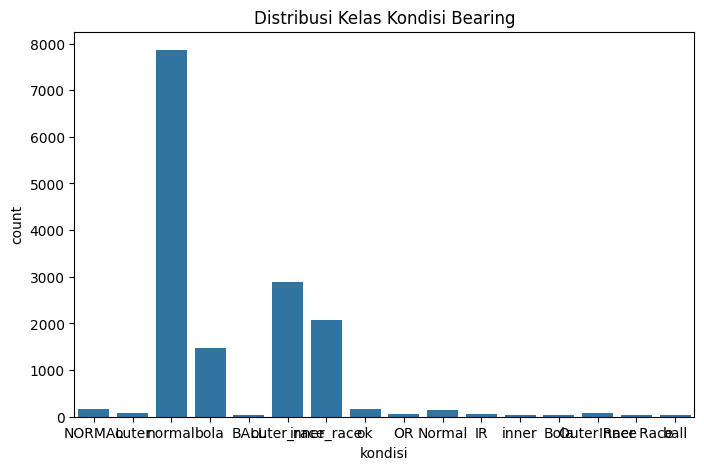

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Memuat Data (Pastikan nama file dan foldernya sesuai)
df = pd.read_csv(url)

print("--- 5 Baris Pertama Data ---")
display(df.head())

# 2. Mengecek Data Kosong dan Tipe Data
print("\n--- Informasi Data ---")
df.info()

print("\n--- Jumlah Data Kosong ---")
print(df.isnull().sum())

# 3. Mengecek Distribusi Kelas (Kondisi Bearing)
print("\n--- Distribusi Kelas 'kondisi' ---")
print(df['kondisi'].value_counts())

# 4. Visualisasi Distribusi Kelas
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='kondisi')
plt.title('Distribusi Kelas Kondisi Bearing')
plt.show()

In [3]:
# Menghapus semua baris yang memiliki nilai kosong
df = df.dropna()

# Memastikan kembali jumlah baris dan ketiadaan data kosong
print(f"Sisa jumlah data sekarang: {len(df)} baris")
print("\nSisa data kosong di tiap kolom:")
print(df.isnull().sum())

Sisa jumlah data sekarang: 14614 baris

Sisa data kosong di tiap kolom:
id_rekaman              0
posisi_sensor           0
kecepatan_rpm           0
beban_kN                0
suhu_housing_C          0
rms_g                   0
puncak_g                0
kurtosis                0
crest_factor            0
energi_bpfo             0
energi_bpfi             0
energi_bsf              0
frekuensi_dominan_hz    0
kondisi                 0
dtype: int64


In [4]:
# Membuat kamus (dictionary) pemetaan untuk menyatukan variasi penulisan
mapping_kondisi = {
    'normal': 'normal', 'ok': 'normal', 'NORMAL': 'normal', 'Normal': 'normal',
    'outer_race': 'outer_race', 'outer': 'outer_race', 'Outer Race': 'outer_race', 'OR': 'outer_race',
    'inner_race': 'inner_race', 'IR': 'inner_race', 'inner': 'inner_race', 'Inner Race': 'inner_race',
    'bola': 'bola', 'BALL': 'bola', 'ball': 'bola', 'Bola': 'bola'
}

# Mengganti nilai di kolom 'kondisi' berdasarkan kamus pemetaan
df['kondisi'] = df['kondisi'].map(mapping_kondisi)

# Mengecek kembali distribusi kelas setelah dirapikan
print("--- Distribusi Kelas 'kondisi' (Setelah Dirapikan) ---")
print(df['kondisi'].value_counts())

--- Distribusi Kelas 'kondisi' (Setelah Dirapikan) ---
kondisi
normal        8003
outer_race    2952
inner_race    2135
bola          1524
Name: count, dtype: int64


In [5]:
# 1. Menghapus kolom 'id_rekaman'
df = df.drop(columns=['id_rekaman'])
print("Kolom 'id_rekaman' berhasil dihapus.")

# 2. Mengubah teks 'posisi_sensor' menjadi angka (Label Encoding)
# drive_end = 0, fan_end = 1
df['posisi_sensor'] = df['posisi_sensor'].map({'drive_end': 0, 'fan_end': 1})
print("Kolom 'posisi_sensor' berhasil diubah menjadi angka.")

# Cek 5 baris pertama untuk memastikan perubahannya
display(df.head())

Kolom 'id_rekaman' berhasil dihapus.
Kolom 'posisi_sensor' berhasil diubah menjadi angka.


,posisi_sensor,kecepatan_rpm,beban_kN,suhu_housing_C,rms_g,puncak_g,kurtosis,crest_factor,energi_bpfo,energi_bpfi,energi_bsf,frekuensi_dominan_hz,kondisi
0,0,2547.0,2.79,53.8,0.5168,1.1658,0.039,2.256,0.1400,0.0436,0.0629,40.9,normal
1,0,1824.0,0.54,47.9,0.3603,1.1888,2.109,3.300,0.1309,0.0031,0.1030,116.0,outer_race
2,0,2865.0,3.72,53.7,0.6982,2.0926,1.224,2.997,0.1902,0.0680,0.1525,46.5,normal
3,0,2796.0,1.15,51.8,0.4973,1.4369,2.706,2.890,0.0788,0.0662,0.0441,46.4,normal
4,1,2419.0,2.09,55.3,0.5089,1.6455,2.894,3.234,0.0230,0.0045,0.1951,82.7,bola


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Memisahkan kolom fitur (X) dan kolom target/jawaban (y)
X = df.drop(columns=['kondisi'])
y = df['kondisi']

# --- LANGKAH 1: SPLIT DATA ---
# Tahap A: Pisahkan 70% untuk Train, sisa 30% untuk Val & Test
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

# Tahap B: Bagi sisa 30% tadi menjadi setengah-setengah (15% Val, 15% Test)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)

print(f"Jumlah data Train: {len(X_train)} baris")
print(f"Jumlah data Validation: {len(X_val)} baris")
print(f"Jumlah data Test: {len(X_test)} baris")

# --- LANGKAH 2: SCALING (STANDARDISASI) ---
scaler = StandardScaler()

# Penting: Model 'belajar' (fit) skala HANYA dari data Train agar tidak curang melihat data uji
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("\nProses Splitting dan Scaling selesai. Data siap dilatih!")

Jumlah data Train: 10229 baris
Jumlah data Validation: 2192 baris
Jumlah data Test: 2193 baris

Proses Splitting dan Scaling selesai. Data siap dilatih!


=== BASELINE LOGISTIC REGRESSION ===
Accuracy: 0.8312043795620438
Macro F1: 0.762355067987944

Classification Report:
              precision    recall  f1-score   support

        bola       0.73      0.49      0.58       229
  inner_race       0.82      0.73      0.77       320
      normal       0.84      0.95      0.89      1200
  outer_race       0.84      0.76      0.80       443

    accuracy                           0.83      2192
   macro avg       0.81      0.73      0.76      2192
weighted avg       0.83      0.83      0.82      2192



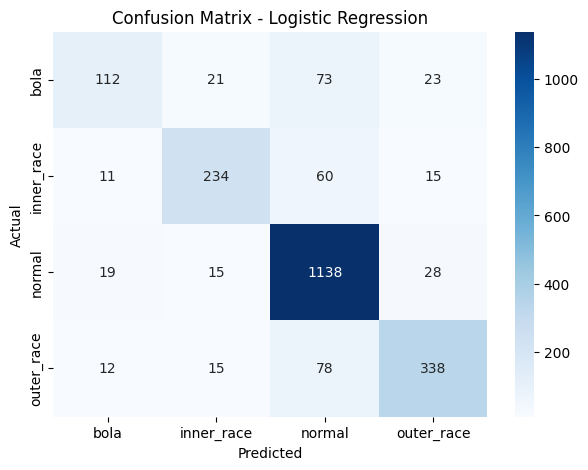

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Membuat model baseline
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Training menggunakan data scaled
lr_model.fit(X_train_scaled, y_train)

# Prediksi validation
y_pred_lr = lr_model.predict(X_val_scaled)

# Evaluasi
print("=== BASELINE LOGISTIC REGRESSION ===")
print("Accuracy:", accuracy_score(y_val, y_pred_lr))
print("Macro F1:", f1_score(y_val, y_pred_lr, average="macro"))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_lr))

# Confusion Matrix
cm = confusion_matrix(y_val, y_pred_lr)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=lr_model.classes_,
    yticklabels=lr_model.classes_
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


=== RANDOM FOREST CLASSIFIER ===
Accuracy: 0.843065693430657
Macro F1: 0.7854594309795797

Classification Report:
              precision    recall  f1-score   support

        bola       0.85      0.48      0.61       229
  inner_race       0.91      0.73      0.81       320
      normal       0.82      0.96      0.88      1200
  outer_race       0.89      0.79      0.84       443

    accuracy                           0.84      2192
   macro avg       0.87      0.74      0.79      2192
weighted avg       0.85      0.84      0.84      2192



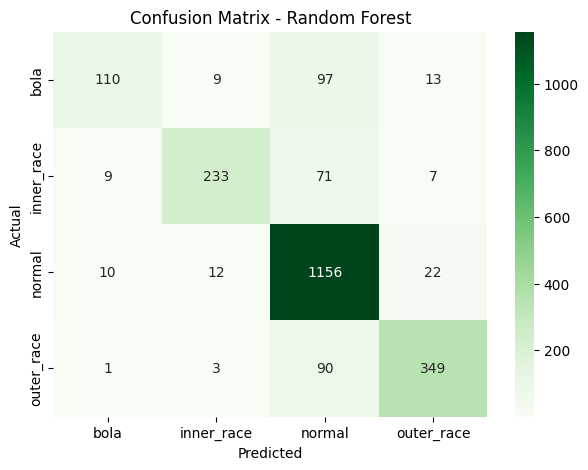

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Membuat model Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Training model
rf_model.fit(X_train, y_train)

# Prediksi data validation
y_pred_rf = rf_model.predict(X_val)

# Evaluasi model
print("=== RANDOM FOREST CLASSIFIER ===")
print("Accuracy:", accuracy_score(y_val, y_pred_rf))
print("Macro F1:", f1_score(y_val, y_pred_rf, average="macro"))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_rf))

# Confusion Matrix
cm_rf = confusion_matrix(y_val, y_pred_rf)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=rf_model.classes_,
    yticklabels=rf_model.classes_
)

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

=== EXTRA TREES CLASSIFIER ===
Accuracy: 0.8403284671532847
Macro F1: 0.7810401536518984

Classification Report:
              precision    recall  f1-score   support

        bola       0.84      0.46      0.59       229
  inner_race       0.92      0.72      0.81       320
      normal       0.81      0.97      0.88      1200
  outer_race       0.92      0.77      0.84       443

    accuracy                           0.84      2192
   macro avg       0.87      0.73      0.78      2192
weighted avg       0.85      0.84      0.83      2192



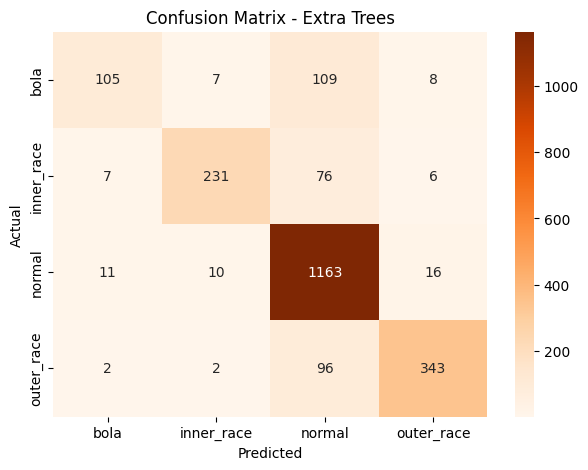

In [9]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Membuat model Extra Trees
et_model = ExtraTreesClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Training model
et_model.fit(X_train, y_train)

# Prediksi validation
y_pred_et = et_model.predict(X_val)

# Evaluasi
print("=== EXTRA TREES CLASSIFIER ===")
print("Accuracy:", accuracy_score(y_val, y_pred_et))
print("Macro F1:", f1_score(y_val, y_pred_et, average="macro"))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_et))

# Confusion Matrix
cm_et = confusion_matrix(y_val, y_pred_et)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_et,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=et_model.classes_,
    yticklabels=et_model.classes_
)

plt.title("Confusion Matrix - Extra Trees")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [10]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

# Model dasar
et_base = ExtraTreesClassifier(
    random_state=42,
    n_jobs=-1
)

# Ruang pencarian parameter
param_dist = {
    "n_estimators": [100, 200, 300, 400],
    "max_depth": [None, 10, 20, 30, 40],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2", None],
    "class_weight": [None, "balanced", "balanced_subsample"]
}

# Randomized Search
random_search = RandomizedSearchCV(
    estimator=et_base,
    param_distributions=param_dist,
    n_iter=20,
    scoring="f1_macro",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Training tuning hanya menggunakan data train
random_search.fit(X_train, y_train)

print("=== HASIL HYPERPARAMETER TUNING ===")
print("Best Parameters:")
print(random_search.best_params_)

print("\nBest CV Macro F1:")
print(random_search.best_score_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


=== HASIL HYPERPARAMETER TUNING ===
Best Parameters:
{'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': None, 'max_depth': 20, 'class_weight': None}

Best CV Macro F1:
0.7815926547666218


=== TUNED EXTRA TREES ===
Accuracy: 0.8512773722627737
Macro F1: 0.8029013572833942

Classification Report:
              precision    recall  f1-score   support

        bola       0.85      0.55      0.66       229
  inner_race       0.90      0.74      0.81       320
      normal       0.82      0.96      0.89      1200
  outer_race       0.92      0.79      0.85       443

    accuracy                           0.85      2192
   macro avg       0.87      0.76      0.80      2192
weighted avg       0.86      0.85      0.85      2192



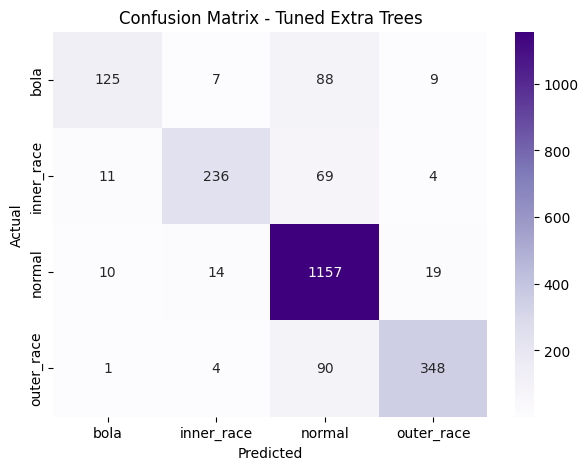

In [11]:
# Mengambil model terbaik
best_et_model = random_search.best_estimator_

# Prediksi validation
y_pred_tuned = best_et_model.predict(X_val)

# Evaluasi
print("=== TUNED EXTRA TREES ===")
print("Accuracy:", accuracy_score(y_val, y_pred_tuned))
print("Macro F1:", f1_score(y_val, y_pred_tuned, average="macro"))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_tuned))

# Confusion Matrix
cm_tuned = confusion_matrix(y_val, y_pred_tuned)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_tuned,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=best_et_model.classes_,
    yticklabels=best_et_model.classes_
)

plt.title("Confusion Matrix - Tuned Extra Trees")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


,Model,Accuracy,Macro F1
0,Tuned Extra Trees,0.851277,0.802901
1,Random Forest,0.843066,0.785459
2,Extra Trees,0.840328,0.781040
3,Logistic Regression,0.831204,0.762355


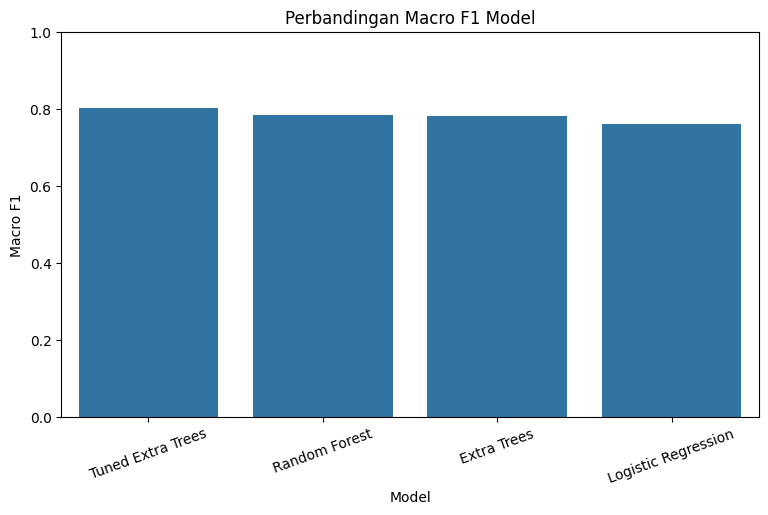

In [12]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Extra Trees",
        "Tuned Extra Trees"
    ],
    "Accuracy": [
        accuracy_score(y_val, lr_model.predict(X_val_scaled)),
        accuracy_score(y_val, y_pred_rf),
        accuracy_score(y_val, y_pred_et),
        accuracy_score(y_val, y_pred_tuned)
    ],
    "Macro F1": [
        f1_score(y_val, lr_model.predict(X_val_scaled), average="macro"),
        f1_score(y_val, y_pred_rf, average="macro"),
        f1_score(y_val, y_pred_et, average="macro"),
        f1_score(y_val, y_pred_tuned, average="macro")
    ]
})

comparison = comparison.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

display(comparison)

# Visualisasi perbandingan Macro F1
plt.figure(figsize=(9, 5))
sns.barplot(
    data=comparison,
    x="Model",
    y="Macro F1"
)
plt.title("Perbandingan Macro F1 Model")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.show()

=== FINAL TEST EVALUATION ===
Accuracy: 0.8426812585499316
Macro F1: 0.7991857164103783

Classification Report:
              precision    recall  f1-score   support

        bola       0.88      0.58      0.70       228
  inner_race       0.91      0.71      0.80       321
      normal       0.81      0.96      0.88      1201
  outer_race       0.89      0.76      0.82       443

    accuracy                           0.84      2193
   macro avg       0.87      0.75      0.80      2193
weighted avg       0.85      0.84      0.84      2193



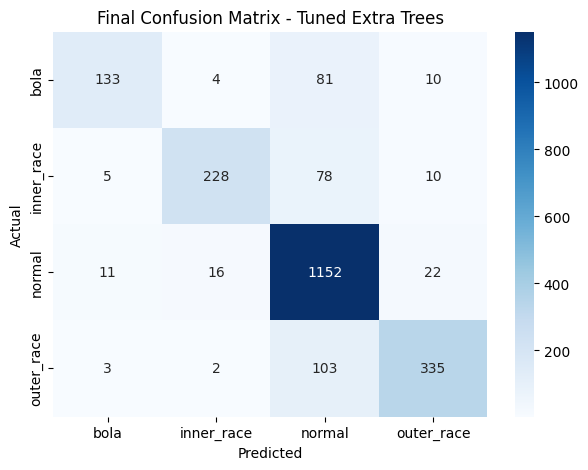

In [13]:
# Menggunakan model terbaik hasil tuning
final_test_model = best_et_model

# Prediksi data test
y_pred_test = final_test_model.predict(X_test)

# Evaluasi akhir
print("=== FINAL TEST EVALUATION ===")

print("Accuracy:",
      accuracy_score(y_test, y_pred_test))

print("Macro F1:",
      f1_score(y_test, y_pred_test, average="macro"))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_test))

# Confusion Matrix
cm_test = confusion_matrix(
    y_test,
    y_pred_test,
    labels=final_test_model.classes_
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_test,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=final_test_model.classes_,
    yticklabels=final_test_model.classes_
)

plt.title("Final Confusion Matrix - Tuned Extra Trees")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [14]:
import os
import json
import joblib
import pandas as pd

# 1. Gabungkan data train dan validation
X_train_final = pd.concat([X_train, X_val], axis=0)
y_train_final = pd.concat([y_train, y_val], axis=0)

print("Jumlah data untuk final training:", len(X_train_final))

# 2. Buat model dengan parameter terbaik
final_model = ExtraTreesClassifier(
    **random_search.best_params_,
    random_state=42,
    n_jobs=-1
)

# 3. Training ulang
final_model.fit(X_train_final, y_train_final)

print("Final model berhasil dilatih!")

# 4. Buat folder models
os.makedirs("models", exist_ok=True)

# 5. Simpan model
joblib.dump(final_model, "models/model.joblib")

# 6. Simpan metadata
metadata = {
    "model_name": "Tuned Extra Trees Classifier",
    "model_type": "ExtraTreesClassifier",
    "target": "kondisi",
    "classes": final_model.classes_.tolist(),
    "features": X_train.columns.tolist(),
    "best_params": random_search.best_params_,
    "validation_macro_f1": float(
        f1_score(y_val, y_pred_tuned, average="macro")
    ),
    "test_macro_f1": float(
        f1_score(y_test, y_pred_test, average="macro")
    ),
    "test_accuracy": float(
        accuracy_score(y_test, y_pred_test)
    )
}

with open("models/metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("\nModel dan metadata berhasil disimpan!")
print("File: models/model.joblib")
print("File: models/metadata.json")

print("\n=== METADATA ===")
print(json.dumps(metadata, indent=4))


Jumlah data untuk final training: 12421
Final model berhasil dilatih!

Model dan metadata berhasil disimpan!
File: models/model.joblib
File: models/metadata.json

=== METADATA ===
{
    "model_name": "Tuned Extra Trees Classifier",
    "model_type": "ExtraTreesClassifier",
    "target": "kondisi",
    "classes": [
        "bola",
        "inner_race",
        "normal",
        "outer_race"
    ],
    "features": [
        "posisi_sensor",
        "kecepatan_rpm",
        "beban_kN",
        "suhu_housing_C",
        "rms_g",
        "puncak_g",
        "kurtosis",
        "crest_factor",
        "energi_bpfo",
        "energi_bpfi",
        "energi_bsf",
        "frekuensi_dominan_hz"
    ],
    "best_params": {
        "n_estimators": 200,
        "min_samples_split": 2,
        "min_samples_leaf": 1,
        "max_features": null,
        "max_depth": 20,
        "class_weight": null
    },
    "validation_macro_f1": 0.8029013572833942,
    "test_macro_f1": 0.7991857164103783,
    "te

In [15]:

%%writefile app.py
import streamlit as st
import pandas as pd
import joblib
import json
import os

# ==========================================
# KONFIGURASI APLIKASI
# ==========================================

st.set_page_config(
    page_title="Bearing Fault Diagnosis",
    page_icon="⚙️",
    layout="wide"
)

MODEL_PATH = "models/model.joblib"
METADATA_PATH = "models/metadata.json"

# ==========================================
# LOAD MODEL DAN METADATA
# ==========================================

@st.cache_resource
def load_model():
    model = joblib.load(MODEL_PATH)

    with open(METADATA_PATH, "r") as file:
        metadata = json.load(file)

    return model, metadata

model, metadata = load_model()

# ==========================================
# HEADER
# ==========================================

st.title("⚙️ Bearing Fault Diagnosis")
st.subheader("Machine Learning-Based Bearing Condition Classification")

st.write(
    "Aplikasi untuk mengidentifikasi kondisi bearing "
    "berdasarkan parameter pengukuran getaran mesin."
)

st.divider()

# ==========================================
# INPUT DATA
# ==========================================

st.header("Input Data Pengukuran")

with st.form("bearing_form"):

    posisi_sensor = st.selectbox(
        "Posisi Sensor",
        ["drive_end", "fan_end"]
    )

    col1, col2 = st.columns(2)

    with col1:
        kecepatan_rpm = st.number_input(
            "Kecepatan (RPM)", min_value=0.0, value=2304.0
        )
        beban_kN = st.number_input(
            "Beban (kN)", min_value=0.0, value=2.3
        )
        suhu_housing_C = st.number_input(
            "Suhu Housing (°C)", value=50.8
        )
        rms_g = st.number_input(
            "RMS (g)", min_value=0.0, value=0.4946
        )
        puncak_g = st.number_input(
            "Puncak (g)", min_value=0.0, value=1.4368
        )
        kurtosis = st.number_input(
            "Kurtosis", value=2.209
        )

    with col2:
        crest_factor = st.number_input(
            "Crest Factor", min_value=0.0, value=2.905
        )
        energi_bpfo = st.number_input(
            "Energi BPFO", min_value=0.0, value=0.0042
        )
        energi_bpfi = st.number_input(
            "Energi BPFI", min_value=0.0, value=0.0834
        )
        energi_bsf = st.number_input(
            "Energi BSF", min_value=0.0, value=0.1533
        )
        frekuensi_dominan_hz = st.number_input(
            "Frekuensi Dominan (Hz)",
            min_value=0.0,
            value=38.7
        )

    submitted = st.form_submit_button(
        "Prediksi Kondisi Bearing",
        use_container_width=True
    )

# ==========================================
# PREDIKSI
# ==========================================

if submitted:

    sensor_mapping = {
        "drive_end": 0,
        "fan_end": 1
    }

    input_data = pd.DataFrame([{
        "posisi_sensor": sensor_mapping[posisi_sensor],
        "kecepatan_rpm": kecepatan_rpm,
        "beban_kN": beban_kN,
        "suhu_housing_C": suhu_housing_C,
        "rms_g": rms_g,
        "puncak_g": puncak_g,
        "kurtosis": kurtosis,
        "crest_factor": crest_factor,
        "energi_bpfo": energi_bpfo,
        "energi_bpfi": energi_bpfi,
        "energi_bsf": energi_bsf,
        "frekuensi_dominan_hz": frekuensi_dominan_hz
    }])

    # Pastikan urutan fitur sama dengan saat training
    input_data = input_data[metadata["features"]]

    prediction = model.predict(input_data)[0]
    probabilities = model.predict_proba(input_data)[0]

    st.divider()
    st.header("Hasil Prediksi")

    st.success(
        f"Kondisi bearing terdeteksi: **{prediction.upper()}**"
    )

    # Probabilitas
    probability_df = pd.DataFrame({
        "Kondisi": model.classes_,
        "Probabilitas": probabilities
    }).sort_values(
        "Probabilitas",
        ascending=False
    )

    st.subheader("Probabilitas Prediksi")

    probability_df["Persentase"] = (
        probability_df["Probabilitas"] * 100
    )

    st.bar_chart(
        probability_df.set_index("Kondisi")["Persentase"]
    )

    # Rekomendasi
    recommendations = {
        "normal": (
            "Bearing dalam kondisi normal. "
            "Lanjutkan pemantauan dan perawatan berkala."
        ),
        "outer_race": (
            "Terindikasi kerusakan outer race. "
            "Lakukan inspeksi dan pertimbangkan penggantian bearing."
        ),
        "inner_race": (
            "Terindikasi kerusakan inner race. "
            "Jadwalkan pemeriksaan dan siapkan komponen pengganti."
        ),
        "bola": (
            "Terindikasi kerusakan elemen bola. "
            "Periksa kondisi bearing dan siapkan komponen pengganti."
        )
    }

    st.subheader("Rekomendasi")
    st.info(recommendations[prediction])

    st.caption(
        "Hasil merupakan prediksi model machine learning "
        "dan perlu dikonfirmasi melalui inspeksi teknis."
    )

# ==========================================
# INFORMASI MODEL
# ==========================================

with st.expander("Informasi Model"):
    st.write("Nama model:", metadata["model_name"])
    st.write("Target:", metadata["target"])
    st.write("Validation Macro F1:", metadata["validation_macro_f1"])
    st.write("Test Macro F1:", metadata["test_macro_f1"])
    st.write("Test Accuracy:", metadata["test_accuracy"])


Writing app.py


In [16]:

%%writefile requirements.txt
streamlit
pandas
numpy
scikit-learn
joblib
matplotlib


Writing requirements.txt


In [22]:

import os

os.makedirs("src", exist_ok=True)

print("Folder src berhasil dibuat!")

Folder src berhasil dibuat!


In [23]:
%%writefile src/features.py

FEATURE_COLUMNS = [
    "posisi_sensor",
    "kecepatan_rpm",
    "beban_kN",
    "suhu_housing_C",
    "rms_g",
    "puncak_g",
    "kurtosis",
    "crest_factor",
    "energi_bpfo",
    "energi_bpfi",
    "energi_bsf",
    "frekuensi_dominan_hz"
]

SENSOR_MAPPING = {
    "drive_end": 0,
    "fan_end": 1
}


def prepare_input(data):
    """
    Menyiapkan input agar sesuai dengan urutan fitur model.
    """
    import pandas as pd

    df = pd.DataFrame([data])
    df["posisi_sensor"] = df["posisi_sensor"].map(SENSOR_MAPPING)

    return df[FEATURE_COLUMNS]


Overwriting src/features.py


In [24]:

%%writefile README.md
# Bearing Fault Diagnosis

## Deskripsi Proyek
Proyek Machine Learning untuk mengklasifikasikan kondisi bearing berdasarkan data getaran mesin.

## Kelas Prediksi
- normal
- outer_race
- inner_race
- bola

## Model
Tuned Extra Trees Classifier.

## Evaluasi
- Validation Macro F1: 0.8029
- Test Macro F1: 0.7992
- Test Accuracy: 0.8427

## Fitur Input
- posisi_sensor
- kecepatan_rpm
- beban_kN
- suhu_housing_C
- rms_g
- puncak_g
- kurtosis
- crest_factor
- energi_bpfo
- energi_bpfi
- energi_bsf
- frekuensi_dominan_hz

## Menjalankan Aplikasi

Install dependencies:

pip install -r requirements.txt

Jalankan Streamlit:

streamlit run app.py

## Struktur Proyek
- app.py
- requirements.txt
- src/features.py
- models/model.joblib
- models/metadata.json
- README.md

## Catatan
Hasil prediksi merupakan alat bantu analisis dan perlu dikonfirmasi melalui inspeksi teknis.


Writing README.md


In [25]:

%%writefile requirements.txt
streamlit
pandas
numpy
scikit-learn
joblib
matplotlib
seaborn


Overwriting requirements.txt


In [26]:

import os

for root, dirs, files in os.walk("."):
    dirs[:] = [d for d in dirs if d not in [".config", ".cache"]]
    for file in files:
        if file.endswith((".py", ".txt", ".json", ".joblib", ".md")):
            print(os.path.join(root, file))


./requirements.txt
./app.py
./README.md
./models/metadata.json
./models/model.joblib
./src/features.py
./sample_data/README.md
./sample_data/anscombe.json


In [31]:

import os
import joblib

model_path = "models/model.joblib"

# Baca model yang sudah disimpan
model = joblib.load(model_path)

# Simpan ulang dengan kompresi
joblib.dump(model, model_path, compress=3)

# Cek ukuran file
size_mb = os.path.getsize(model_path) / (1024 * 1024)

print(f"Ukuran model setelah kompresi: {size_mb:.2f} MB")

if size_mb < 25:
    print("Aman untuk diupload ke GitHub!")
else:
    print("Masih terlalu besar. Kita gunakan alternatif lain.")


Ukuran model setelah kompresi: 19.10 MB
Aman untuk diupload ke GitHub!


In [32]:

import os
import shutil

project_folder = "bearing-diagnostic-system"

# Pastikan folder proyek tersedia
os.makedirs(project_folder, exist_ok=True)

# Salin ulang seluruh file terbaru
for item in ["app.py", "requirements.txt", "README.md", "models", "src"]:
    destination = os.path.join(project_folder, item)

    if os.path.isdir(item):
        shutil.copytree(item, destination, dirs_exist_ok=True)
    else:
        shutil.copy2(item, destination)

# Hapus ZIP lama jika ada
zip_name = "bearing-diagnostic-system.zip"

if os.path.exists(zip_name):
    os.remove(zip_name)

# Buat ZIP baru
shutil.make_archive(
    "bearing-diagnostic-system",
    "zip",
    root_dir=".",
    base_dir=project_folder
)

print("ZIP BARU BERHASIL DIBUAT!")
print("Ukuran ZIP:", round(os.path.getsize(zip_name) / (1024*1024), 2), "MB")


ZIP BARU BERHASIL DIBUAT!
Ukuran ZIP: 18.9 MB


In [33]:
from google.colab import files
files.download("bearing-diagnostic-system.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>